# M1b rerun: fast WERM and unpenalized fold-count comparison

Self-contained adaptation of the two corresponding experiments in `M1_upsample_redo`. Data generation, estimator calls, CV, 36-worker parallel execution, aggregation, serialization, and plotting are visible and execute directly below; no external runner is imported. All WERM CV scoring is absolute loss. Unpenalized Huber WERM is compared with 2, 5, and 10 folds; alpha=0.3 L1 methods retain exhaustive 2-fold CV.

## M1b alpha 0.3

In [1]:
from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
jax.config.update('jax_enable_x64', True)
import numpy.random as nprandom
import matplotlib.pyplot as plt
# Embed figures in executed notebook output even on a headless compute node.
plt.switch_backend("module://matplotlib_inline.backend_inline")
from functools import partial
from tqdm.auto import tqdm
from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv
import time
from joblib import Parallel, delayed
import sys
import pickle
import os
os.environ['JAX_ENABLE_X64']='True'

# Set a random seed for reproducibility
random_seed = 46
SMOKE_MODE = os.environ.get('WERM_SMOKE') == '1'

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, fixed_noise_scale, fractional_chgpt_locations, M, gamma_candidates, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    i, delta, j = params # delta is now the iterating parameter

    rng = _trial_rng("M1b-alpha-0.3", i, j)

    # --- Setup based on delta and fixed noise_scale ---
    n = int(delta * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    # Sparse Difference Signal Prior
    # α = 0.5 # fraction of nonzeros in change vector
    # var_β_1 = 8
    # σ_w = np.sqrt(400*delta) # standard deviation of the signal perturbation
    # signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)
    
    κ = 1.0
    α = 0.3 # Fraction of nonzeros
    σ_l_arr = κ * np.sqrt(delta) * np.ones(L)  # Signal standard deviations
    signal_prior = SparseGaussianSignal(α, delta, σ_l_arr)

    # --- Data Generation for this trial ---
    B̃ = signal_prior.sample(p, rng=rng)
    # print("B̃ shape:", B̃.shape) # Keep for debugging if needed
    X = rng.normal(0, np.sqrt(1/n), (n, p))
    # ε = nprandom.normal(0, 1, size=(n,)) * fixed_noise_scale # Using fixed_noise_scale here
    ε = rng.standard_t(4, size=(n, )) * fixed_noise_scale # For Huber loss, use t-distribution for noise. df > 2 has finite variance.


    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
    y_standardized = np.array(y / np.std(y))  # Standardize y

    # --- Run Estimators for all configured methods ---
    trial_results = {'data_hash': _data_hash(X, y)}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            # print(f"Running {method_name} on params: ", params) # Keep for debugging if needed
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'McScan':
                # print(f"Input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).shape}") # Keep for debugging if needed
                # print(f"New input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).reshape((n, 1)).shape}") # Keep for debugging if needed
                cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), y_standardized.flatten(), num_chgpts = None, method='auto'))
                # print(f"McScan res: {cp}") # Keep for debugging if needed
                cp = np.array([c for c in cp if c != -1], dtype=int)  # Remove -1s and convert to 0-indexed
            elif method_name == 'DCDP':
                cp = np.asarray(WERM.comparison.DCDP(np.array(X_scaled), y_standardized))
                # print(f"True changepoints: {true_chgpts}, DCDP changepoints: {cp}") # Keep for debugging if needed
            elif method_name == 'DPDU':
                cp = np.asarray(WERM.comparison.DPDU(np.array(X_scaled), y_standardized, λs = [0.01, 0.1, 1, 2], ζs = [10.0, 15.0, 20.0]))
                cp = np.array([c for c in cp if c != -1], dtype=int)  # Remove -1s and convert to 0-indexed
            elif method_name == 'MOSEG':
                res = WERM.comparison.MOSEG(np.array(X_scaled), y_standardized, ms=True, num_chgpts = None)
                cp = res[1]  # Extract the refined estimate; R NULL means no change found.
                if cp is WERM.comparison.rpy2.rinterface.NULL:
                    cp = np.array([], dtype=int)
                else:
                    cp = np.array([c for c in cp if c != -1], dtype=int)
            elif method_name == 'charcoal':
                cp = WERM.comparison.run_charcoal(np.array(X_scaled), np.array(y))
            elif method_name == 'WERM-CV':
                Delta = lambda n_len: 1
                # Run cross-validation to find the best regularisation penalty parameter
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""

                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_,
                        coefficient_loss="huber", coefficient_lambda=l1_reg_param,
                        huber_delta=1.35,
                    )

                # Perform cross-validation to find the best gamma
                best_l1_reg, best_model_output = WERM.estimators.chgpt_k_fold_cv(
                    f=WERM_l1_reg_paramCV,
                    X=X,
                    y=y,
                    gamma_candidates=[1e-4, 1e-3, 1e-2],
                    M_scorer=M_scorer,
                    P_scorer=None,
                    k=5,
                    n_jobs=1
                )

                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=0.0,
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func,
                    coefficient_loss="huber", coefficient_lambda=best_l1_reg,
                    huber_delta=1.35,
                )
            elif method_name == 'WERM-L1-jointCV':
                (best_segments, best_C), cp = _weighted_erm_joint_cv(
                    X=X_scaled, y=np.asarray(y), M=M, M_scorer=M_scorer,
                    Lmax=L, delta_fraction=1/20, standardize_y=True,
                    l1_constants=(0.03, 0.3, 3.0), num_folds=2, n_jobs=1,
                    selection_strategy='exhaustive', coefficient_loss='huber', huber_delta=1.35,
                    coefficient_solver_options={'tol': 1e-5, 'max_iter': 50000},
                )
                trial_results['selected_segments_WERM-L1-jointCV'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-jointCV'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-jointCV'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-jointCV'] = float(best_C*np.sqrt(2*np.log(p)/n))
            elif method_name == 'WERM-L1-C0.3-CV':
                (best_segments, _), cp = _weighted_erm_joint_cv(
                    X=X_scaled, y=np.asarray(y), M=M, M_scorer=M_scorer,
                    Lmax=L, delta_fraction=1/20, standardize_y=True,
                    l1_constants=(0.3,), num_folds=2, n_jobs=1,
                    selection_strategy='exhaustive', coefficient_loss='huber', huber_delta=1.35,
                    coefficient_solver_options={'tol': 1e-5, 'max_iter': 50000},
                )
                trial_results['selected_segments_WERM-L1-C0.3-CV'] = int(best_segments)
            elif method_name.startswith('WERM-unp-'):
                # Identical data and absolute held-out score; only k changes.
                num_cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                (best_segments, _), cp = _weighted_erm_joint_cv(
                    X=X_scaled, y=y_standardized, M=M, M_scorer=M_scorer,
                    Lmax=L, delta_fraction=1/20, l1_constants=(0.0,),
                    num_folds=num_cv_folds, n_jobs=1, standardize_y=False,
                    selection_strategy='exhaustive', penalty_norm='none',
                    coefficient_loss='huber', huber_delta=1.35,
                    coefficient_solver_options={'tol': 1e-5, 'max_iter': 50000},
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                print(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            evaluation = _evaluate_changepoints(cp, true_chgpts, n)
            raw_cp = evaluation['raw_cp']
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
            trial_results[f'status_{method_name}'] = evaluation['status']
            haus_value = evaluation['haus']
            if evaluation['status'] == 'empty_estimate':
                haus_value = np.nan
            trial_results[f'haus_{method_name}'] = haus_value
            trial_results[f'size_{method_name}'] = evaluation['size']
            trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
            methods_status[method_name] = evaluation['status'] != 'not_applicable'

        except Exception as e:
            print(f"Trial {j+1} for delta={delta:.1f}: {method_name} failed with error: {e}")
            raise

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status


    return i, j, trial_results

# --- Main Script Setup ---

# Simulation Parameters
p = 200
L = 4
fixed_noise_scale = np.sqrt(0.1) # Noise scale is now fixed
delta_list = np.arange(1.0, 10.0, 1.0) # Iterate over delta
num_trials = 100
fractional_chgpt_locations = np.array([0.35, 0.65])
n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
if SMOKE_MODE:
    delta_list = np.array([3.0])
    num_trials = 1
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '2')), 36))

r = 0.4 # Charcoal requires i.i.d covariates
Sigma = np.eye(p)
for i_cov in range(p):
    for j_cov in range(p):
        if i_cov != j_cov:
            Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# Sigma = sample_corr(p, df=10, seed=random_seed) 

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'McScan', 'label': r'\textbf{McScan}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'WERM-unp-2fold', 'label': r'\textbf{WERM unpen. (2-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-unp-5fold', 'label': r'\textbf{WERM unpen. (5-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-10fold', 'label': r'\textbf{WERM unpen. (10-fold)}', 'color': '#999999', 'marker': 'P', 'linestyle': ':'},
    {'name': 'WERM-L1-jointCV', 'label': r'\textbf{WERM-L1 full joint CV}', 'color': '#0077BB', 'marker': 's', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-CV', 'label': r'\textbf{WERM-L1 C=0.3}', 'color': '#33BBEE', 'marker': 'v', 'linestyle': '--'},
    {'name': 'DCDP', 'label': r'\textbf{DCDP}', 'color': '#EE6677', 'marker': '^', 'linestyle': '-.'},
    {'name': 'DPDU', 'label': r'\textbf{DPDU}', 'color': '#4477AA', 'marker': 'D', 'linestyle': '--'},
    {'name': 'MOSEG', 'label': r'\textbf{MOSEG}', 'color': '#228833', 'marker': 'x', 'linestyle': ':'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names


# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': [] # Renamed from noise_scale_values
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []

# Loss Function (Least Squares)
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

M_scorer = lambda u, v: jnp.abs(u - v)

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-1, 2, 5)

# --- Parallel Execution ---
tasks = [(i, delta, j) for i, delta in enumerate(delta_list) for j in range(num_trials)]

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            fixed_noise_scale=fixed_noise_scale, # Pass fixed noise_scale
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )
except Exception as e:
    print(f"Simulation failed with error: {str(e)}")
    raise

# --- Aggregate Results ---

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, delta_list[i])) # Store delta

results['trial_records'] = parallel_results
results['summaries'] = []
for setting_idx, setting in enumerate(delta_list):
    setting_records = [record for i, _, record in parallel_results if i == setting_idx]
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        summary = _summarize_setting(
            [record[f'haus_{method_name}'] for record in setting_records],
            [record[f'size_{method_name}'] for record in setting_records],
            [record[f'status_{method_name}'] for record in setting_records],
        )
        summary.update({'method': method_name, 'setting': float(setting)})
        results['summaries'].append(summary)
        print(method_name, f"delta={setting:.3g}", summary)

Running simulation trials:   0%|                                            | 0/900 [00:00<?, ?it/s]

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
A

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 31.  71. 134. 176.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 47.  80. 169.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 62. 125.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 93. 163.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 57.  87. 177.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 29.  74. 129. 152.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [59. 79.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
Runnin

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00, 17.89it/s]

100%|██████████| 1/1 [00:00<00:00, 15.18it/s]

  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00, 14.27it/s]

100%|██████████| 1/1 [00:00<00:00, 14.13it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00, 14.11it/s]

100%|██████████| 1/1 [00:00<00:00, 14.14it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00, 1416.99it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


... (79,404 outputs left out)

MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]


MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]


MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]


McScan delta=1 {'mean_haus': 0.18525000000000003, 'median_haus': 0.2, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 3.48, 'method': 'McScan', 'setting': 1.0}
WERM-unp-2fold delta=1 {'mean_haus': 0.19870000000000002, 'median_haus': 0.1875, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.52, 'method': 'WERM-unp-2fold', 'setting': 1.0}
WERM-unp-5fold delta=1 {'mean_haus': 0.17504999999999998, 'median_haus': 0.185, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.85, 'method': 'WERM-unp-5fold', 'setting': 1.0}
WERM-unp-10fold delta=1 {'mean_haus': 0.18064999999999998, 'median_haus': 0.19, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.81, 'method': 'WERM-unp-10fold', 'setting': 1.0}
WERM-L1-jointCV delta=1 {'mean_haus': 0.3559701492537313, 'median_haus': 0.34, 'empty_estimate_rate': 0.33, 'not_applicable_rate': 0.0, 'mean_size': 1.27, 'method': 'WERM-L1-jointCV', 'setting': 1.0}
WERM-L1-C0.3-CV delt

### Plots

Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377', '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33'] (Paul Tol Vibrant assigned to methods)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...
MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]


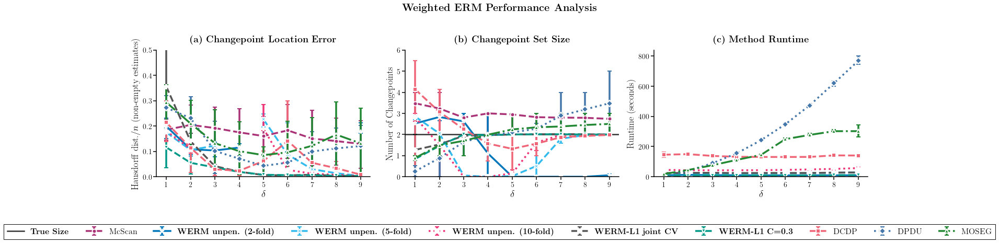

2. Confidence bands (publication style)...


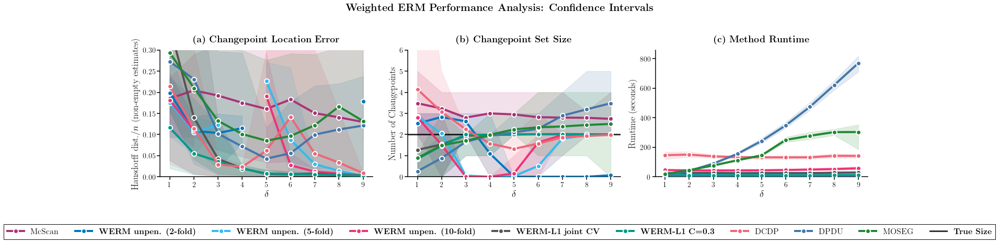

3. Box plots (publication style)...
No valid data for WERM-unp-10fold for delta 3.0 (haus). Skipping box plot for this point.
No valid data for WERM-unp-5fold for delta 4.0 (haus). Skipping box plot for this point.
No valid data for WERM-unp-10fold for delta 4.0 (haus). Skipping box plot for this point.
No valid data for WERM-unp-2fold for delta 5.0 (haus). Skipping box plot for this point.
No valid data for WERM-unp-2fold for delta 6.0 (haus). Skipping box plot for this point.
No valid data for WERM-unp-2fold for delta 7.0 (haus). Skipping box plot for this point.
No valid data for WERM-unp-2fold for delta 8.0 (haus). Skipping box plot for this point.


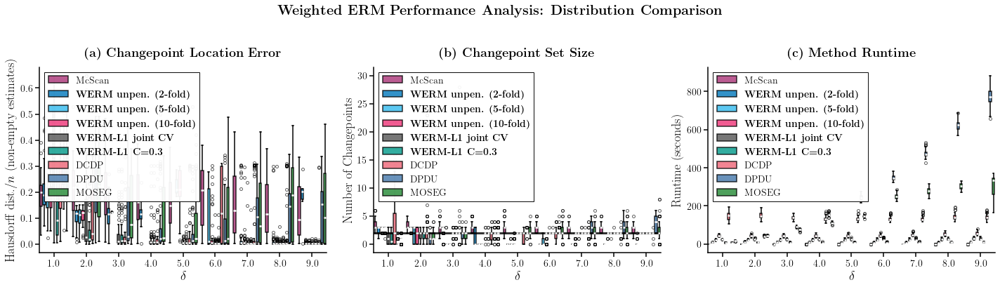

4. Enhanced changepoint histograms (publication style)...


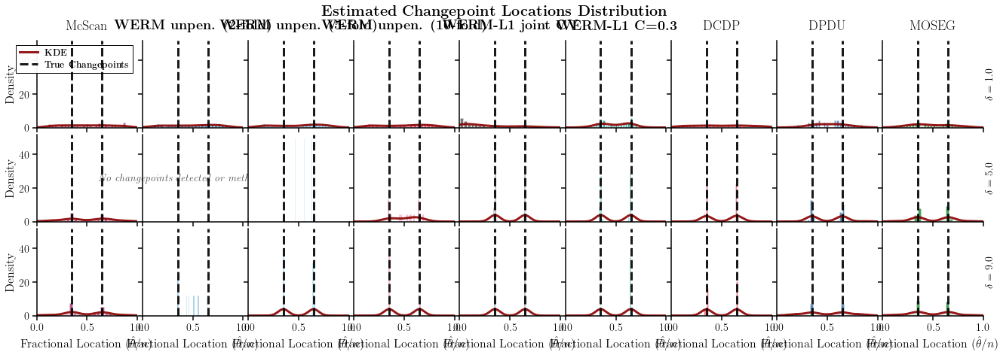

Saving results to results/M1_upsample_b_alpha03_cp035065_McScan_WERM-unp-2fold_WERM-unp-5fold_WERM-unp-10fold_WERM-L1-jointCV_WERM-L1-C0.3-CV_DCDP_DPDU_MOSEG_results_p200_L4_delta123456789_noisecale0.316_seed46.pkl...


In [2]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})


# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        # Set all infs to NaN for plotting
        data = np.where(np.isinf(data), np.nan, data)
        # Calculate means and asymmetric errors
        # Using np.nanmean to ignore NaNs in the calculation
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Hausdorff dist./$n$ (non-empty estimates)', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff dist./$n$ (non-empty estimates)', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                print(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(delta_list, p10, p90, color=plot_colors[method_idx], # Changed x-axis to delta_list
                            alpha=0.15, zorder=1)
            ax.plot(delta_list, means, color=plot_colors[method_idx], linewidth=4, # Changed x-axis to delta_list
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(delta_list) # Changed x-ticks
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff dist./$n$ (non-empty estimates)', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta_val in enumerate(delta_list): # Iterating over delta_list
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    print(f"No valid data for {method_name} for delta {delta_val:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(delta_list))]
        ax.set_xticks(delta_positions) # Changed x-ticks to delta_positions
        ax.set_xticklabels([f'{d:.1f}' for d in delta_list]) # Changed x-tick labels
        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                         for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                   frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_delta_idx = list(range(len(delta_list)))[::4]
    selected_deltas = delta_list[::4]
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(2.5 * len(methods_to_plot_names), 2.2 * len(selected_deltas)),
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08})

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    # Use the fixed_noise_scale defined globally
    global fixed_noise_scale # Access the global fixed_noise_scale

    for row, (delta_idx, delta_val) in enumerate(zip(selected_delta_idx, selected_deltas)):
        n = int(delta_val * p) # n depends on delta, which is now the varying parameter
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                         color=method_plotting_info[method_name]['color'],
                         density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                             alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                         transform=ax.transAxes, ha='center', va='center',
                         fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                                 alpha=0.9, zorder=10,
                                 label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$\delta = {delta_val}$', transform=ax.transAxes, # Changed to delta
                                 rotation=90, verticalalignment='center', fontsize=14,
                                 fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                         edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
# Final M1b plotting format: Tol-bright competitors and black hero WERM.
_FINAL_M1B_STYLES = {
    'McScan': dict(label='McScan', color='#AA3377', marker='o', linestyle='--', linewidth=1.5, zorder=5),
    'MOSEG': dict(label='MOSEG', color='#228833', marker='^', linestyle='-.', linewidth=1.5, zorder=5),
    'DPDU': dict(label='DPDU', color='#4477AA', marker='D', linestyle=':', linewidth=1.5, zorder=5),
    'DCDP': dict(label='DCDP', color='#EE6677', marker='s', linestyle='--', linewidth=1.5, zorder=5),
    'charcoal': dict(label='charcoal', color='#66CCEE', marker='v', linestyle='-.', linewidth=1.5, zorder=5),
    'GLMBSA': dict(label='GLMBSA', color='#E69F00', marker='p', linestyle=':', linewidth=1.5, zorder=5),
    'GLMBSA-CV': dict(label='GLMBSA-CV', color='#CCBB44', marker='d', linestyle='--', linewidth=1.5, zorder=6),
    'WERM-unp': dict(label=r'\textbf{WERM (Huber score)}', color='black', marker='*', linestyle='-', linewidth=2.5, zorder=10),
    'WERM-unp-abs': dict(label=r'\textbf{WERM (absolute score)}', color='#555555', marker='X', linestyle='--', linewidth=2.2, zorder=9),
    'WERM-CV': dict(label=r'\textbf{WERM-CV}', color='black', marker='*', linestyle='-', linewidth=2.5, zorder=10),
    'WERM-L1-jointCV': dict(label=r'\textbf{WERM-L1 joint CV}', color='#555555', marker='P', linestyle='--', linewidth=2.2, zorder=9),
}
for _method in methods_to_evaluate:
    _method.update(_FINAL_M1B_STYLES.get(_method['name'], {}))
PAL = [_method['color'] for _method in methods_to_evaluate]

print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, method_names_list)

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Updated filename to reflect fixed noise_scale and varying delta
filename = f"results/M1_upsample_b_alpha03_cp035065_{method_names_for_filename}_results_p{p}_L{L}_delta{''.join(map(str, map(int, delta_list)))}_noisecale{fixed_noise_scale:.3f}_seed{random_seed}.pkl"
if SMOKE_MODE: filename = filename.replace('.pkl', '_smoke.pkl')
print(f"Saving results to {filename}...")
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'delta_list': delta_list, # Updated to delta_list
            'fixed_noise_scale': fixed_noise_scale, # Stored fixed_noise_scale
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'joint_l1_constants': np.array([0.03, 0.3, 3.0]), 'num_folds_l1': 2, 'num_folds_unpenalized': (2, 5, 10),
            'random_seed': random_seed
        }
    }, f)

## M1b alpha 1.0 dense redo

In [3]:
from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
jax.config.update('jax_enable_x64', True)
import numpy.random as nprandom
import matplotlib.pyplot as plt
# Embed figures in executed notebook output even on a headless compute node.
plt.switch_backend("module://matplotlib_inline.backend_inline")
from functools import partial
from tqdm.auto import tqdm
from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv
import time
from joblib import Parallel, delayed
import sys
import pickle
import os
os.environ['JAX_ENABLE_X64']='True'

# Set a random seed for reproducibility
random_seed = 46
SMOKE_MODE = os.environ.get('WERM_SMOKE') == '1'

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, fixed_noise_scale, fractional_chgpt_locations, M, gamma_candidates, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    i, delta, j = params # delta is now the iterating parameter

    rng = _trial_rng("M1b-alpha-1.0-redo", i, j)

    # --- Setup based on delta and fixed noise_scale ---
    n = int(delta * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    # Sparse Difference Signal Prior
    # α = 0.5 # fraction of nonzeros in change vector
    # var_β_1 = 8
    # σ_w = np.sqrt(400*delta) # standard deviation of the signal perturbation
    # signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)
    
    κ = 1.0
    α = 1.0 # Fully dense signal
    σ_l_arr = κ * np.sqrt(delta) * np.ones(L)  # Signal standard deviations
    signal_prior = SparseGaussianSignal(α, delta, σ_l_arr)

    # --- Data Generation for this trial ---
    B̃ = signal_prior.sample(p, rng=rng)
    # print("B̃ shape:", B̃.shape) # Keep for debugging if needed
    X = rng.normal(0, np.sqrt(1/n), (n, p))
    # ε = nprandom.normal(0, 1, size=(n,)) * fixed_noise_scale # Using fixed_noise_scale here
    ε = rng.standard_t(4, size=(n, )) * fixed_noise_scale # For Huber loss, use t-distribution for noise. df > 2 has finite variance.


    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
    y_standardized = np.array(y / np.std(y))  # Standardize y

    # --- Run Estimators for all configured methods ---
    trial_results = {'data_hash': _data_hash(X, y)}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            # print(f"Running {method_name} on params: ", params) # Keep for debugging if needed
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'McScan':
                # print(f"Input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).shape}") # Keep for debugging if needed
                # print(f"New input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).reshape((n, 1)).shape}") # Keep for debugging if needed
                cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), y_standardized.flatten(), num_chgpts = None, method='auto'))
                # print(f"McScan res: {cp}") # Keep for debugging if needed
                cp = np.array([c for c in cp if c != -1], dtype=int)  # Remove -1s and convert to 0-indexed
            elif method_name == 'DCDP':
                cp = np.asarray(WERM.comparison.DCDP(np.array(X_scaled), y_standardized))
                # print(f"True changepoints: {true_chgpts}, DCDP changepoints: {cp}") # Keep for debugging if needed
            elif method_name == 'DPDU':
                if delta <= 7.0: 
                    cp = np.asarray(WERM.comparison.DPDU(np.array(X_scaled), y_standardized, λs = [0.01, 0.1, 1, 2], ζs = [10.0, 15.0, 20.0]))
                    cp = np.array([c for c in cp if c != -1], dtype=int)  # Remove -1s and convert to 0-indexed
                else: 
                    cp = np.array([])
            elif method_name == 'MOSEG':
                res = WERM.comparison.MOSEG(np.array(X_scaled), y_standardized, ms=True, num_chgpts = None)
                cp = res[1]  # Extract the refined estimate; R NULL means no change found.
                if cp is WERM.comparison.rpy2.rinterface.NULL:
                    cp = np.array([], dtype=int)
                else:
                    cp = np.array([c for c in cp if c != -1], dtype=int)
            elif method_name == 'charcoal':
                cp = WERM.comparison.run_charcoal(np.array(X_scaled), np.array(y))
            elif method_name == 'WERM-CV':
                Delta = lambda n_len: 1
                # Run cross-validation to find the best regularisation penalty parameter
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""

                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_,
                        coefficient_loss="huber", coefficient_lambda=l1_reg_param,
                        huber_delta=1.35,
                    )

                # Perform cross-validation to find the best gamma
                best_l1_reg, best_model_output = WERM.estimators.chgpt_k_fold_cv(
                    f=WERM_l1_reg_paramCV,
                    X=X,
                    y=y,
                    gamma_candidates=[1e-4, 1e-3, 1e-2],
                    M_scorer=M_scorer,
                    P_scorer=None,
                    k=5,
                    n_jobs=1
                )

                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=0.0,
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func,
                    coefficient_loss="huber", coefficient_lambda=best_l1_reg,
                    huber_delta=1.35,
                )
            elif method_name == 'WERM-L1-jointCV':
                delta_fraction = 1/20
                (best_segments, best_C), cp = _weighted_erm_joint_cv(
                    X=X_scaled, y=np.asarray(y), M=M, M_scorer=M_scorer,
                    Lmax=L, delta_fraction=delta_fraction, standardize_y=True,
                    l1_constants=(0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0),
                    num_folds=5, n_jobs=1,
                    coefficient_loss="huber", huber_delta=1.35,
                )
                trial_results['selected_segments_WERM-L1-jointCV'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-jointCV'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-jointCV'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-jointCV'] = float(
                    best_C * np.sqrt(2 * np.log(p) / n)
                )

            elif method_name.startswith('WERM-unp-'):
                # Identical data and absolute held-out score; only k changes.
                num_cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                (best_segments, _), cp = _weighted_erm_joint_cv(
                    X=X_scaled, y=y_standardized, M=M, M_scorer=M_scorer,
                    Lmax=L, delta_fraction=1/20, l1_constants=(0.0,),
                    num_folds=num_cv_folds, n_jobs=1, standardize_y=False,
                    selection_strategy='exhaustive', penalty_norm='none',
                    coefficient_loss='huber', huber_delta=1.35,
                    coefficient_solver_options={'tol': 1e-5, 'max_iter': 50000},
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                print(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            evaluation = _evaluate_changepoints(cp, true_chgpts, n)
            raw_cp = evaluation['raw_cp']
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
            trial_results[f'status_{method_name}'] = evaluation['status']
            haus_value = evaluation['haus']
            if evaluation['status'] == 'empty_estimate':
                haus_value = np.nan
            trial_results[f'haus_{method_name}'] = haus_value
            trial_results[f'size_{method_name}'] = evaluation['size']
            trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
            methods_status[method_name] = evaluation['status'] != 'not_applicable'

        except Exception as e:
            print(f"Trial {j+1} for delta={delta:.1f}: {method_name} failed with error: {e}")
            raise

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status


    return i, j, trial_results

# --- Main Script Setup ---

# Simulation Parameters
p = 200
L = 4
fixed_noise_scale = np.sqrt(0.1) # Noise scale is now fixed
delta_list = np.arange(2.0, 10.0, 1.0) # Iterate over delta
num_trials = 100
fractional_chgpt_locations = np.array([0.35, 0.65])
n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36)) # Always try to run 36 jobs
if SMOKE_MODE:
    delta_list = np.array([3.0])
    num_trials = 1
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '2')), 36))

r = 0.4 # Charcoal requires i.i.d covariates
Sigma = np.eye(p)
for i_cov in range(p):
    for j_cov in range(p):
        if i_cov != j_cov:
            Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)

# Sigma = sample_corr(p, df=10, seed=random_seed) 

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'McScan', 'label': r'\textbf{McScan}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'WERM-unp-2fold', 'label': r'\textbf{WERM unpen. (2-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-unp-5fold', 'label': r'\textbf{WERM unpen. (5-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-10fold', 'label': r'\textbf{WERM unpen. (10-fold)}', 'color': '#999999', 'marker': 'P', 'linestyle': ':'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names


# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': [] # Renamed from noise_scale_values
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []

# Loss Function (Least Squares)
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

M_scorer = lambda u, v: jnp.abs(u - v) # Always use the absolute value loss for CV scoring!

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-1, 2, 5)

# --- Parallel Execution ---
tasks = [(i, delta, j) for i, delta in enumerate(delta_list) for j in range(num_trials)]

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            fixed_noise_scale=fixed_noise_scale, # Pass fixed noise_scale
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )
except Exception as e:
    print(f"Simulation failed with error: {str(e)}")
    raise

# --- Aggregate Results ---

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, delta_list[i])) # Store delta

results['trial_records'] = parallel_results
results['summaries'] = []
for setting_idx, setting in enumerate(delta_list):
    setting_records = [record for i, _, record in parallel_results if i == setting_idx]
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        summary = _summarize_setting(
            [record[f'haus_{method_name}'] for record in setting_records],
            [record[f'size_{method_name}'] for record in setting_records],
            [record[f'status_{method_name}'] for record in setting_records],
        )
        summary.update({'method': method_name, 'setting': float(setting)})
        results['summaries'].append(summary)
        print(method_name, f"delta={setting:.3g}", summary)

Running simulation trials:   0%|                                            | 0/800 [00:00<?, ?it/s]

MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [ 55. 245.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [132. 159. 281.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [167. 218. 242.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]
Running McScan with automatic changepoint estimation.
Estimated changepoints from McScan:  [150. 199. 305.]
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
MOSEG effective Gset (package default, clipped to n/2): [133, 177, 222]
Running McScan with automatic changepoint estimation.
Estimated changepoi

100%|██████████| 1/1 [00:00<00:00, 1072.44it/s]


\Delta: 2, n: 50, Lmin: 1, Lmax: 1
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
\Delta: 2, n: 50, Lmin: 1, Lmax: 1


100%|██████████| 1/1 [00:00<00:00, 1794.74it/s]


\Delta: 2, n: 50, Lmin: 2, Lmax: 2
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
\Delta: 2, n: 50, Lmin: 1, Lmax: 1
\Delta: 2, n: 50, Lmin: 1, Lmax: 1


... (16,498 outputs left out)

100%|██████████| 1/1 [00:00<00:00, 151.93it/s]


\Delta: 2, n: 50, Lmin: 3, Lmax: 3


100%|██████████| 1/1 [00:00<00:00, 157.87it/s]


McScan delta=2 {'mean_haus': 0.20375, 'median_haus': 0.21875, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 3.15, 'method': 'McScan', 'setting': 2.0}
WERM-unp-2fold delta=2 {'mean_haus': 0.11207500000000001, 'median_haus': 0.1175, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.74, 'method': 'WERM-unp-2fold', 'setting': 2.0}
WERM-unp-5fold delta=2 {'mean_haus': 0.11588541666666669, 'median_haus': 0.12, 'empty_estimate_rate': 0.04, 'not_applicable_rate': 0.0, 'mean_size': 2.81, 'method': 'WERM-unp-5fold', 'setting': 2.0}
WERM-unp-10fold delta=2 {'mean_haus': 0.11723684210526317, 'median_haus': 0.1225, 'empty_estimate_rate': 0.05, 'not_applicable_rate': 0.0, 'mean_size': 2.84, 'method': 'WERM-unp-10fold', 'setting': 2.0}
McScan delta=3 {'mean_haus': 0.19041666666666665, 'median_haus': 0.17833333333333334, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 3.0, 'method': 'McScan', 'setting': 3.0}
WERM-unp-2fold delta=3 {'mean

### Plots

Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant assigned to methods)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...


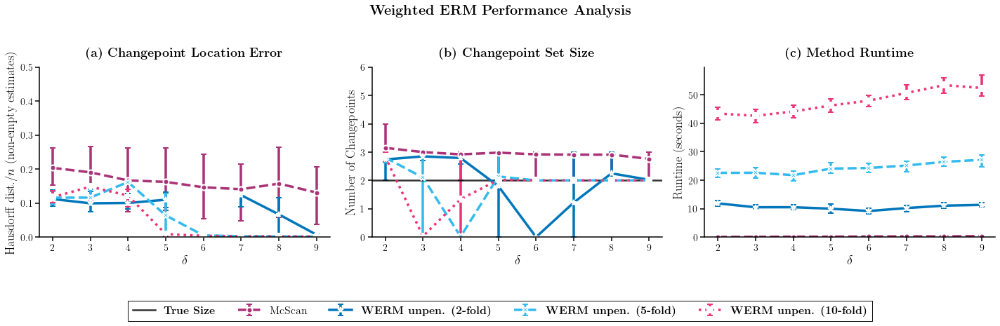

2. Confidence bands (publication style)...


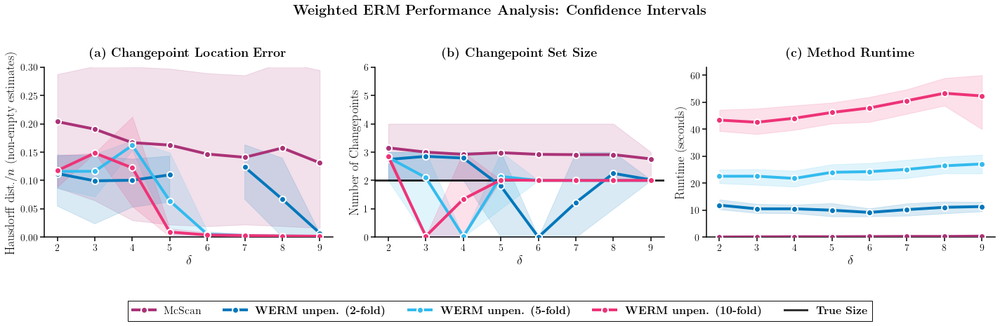

3. Box plots (publication style)...


No valid data for WERM-unp-2fold for delta 6.0 (haus). Skipping box plot for this point.


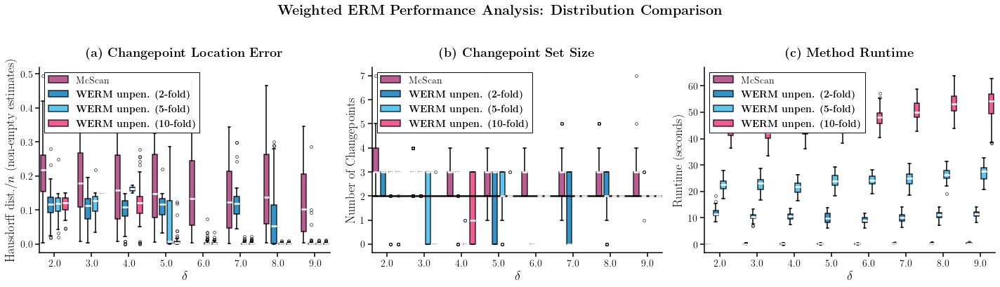

4. Enhanced changepoint histograms (publication style)...


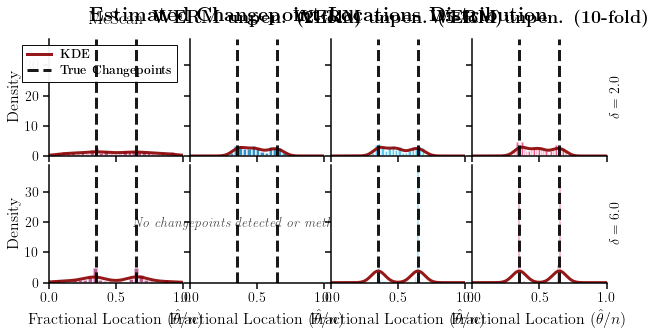

Saving results to results/M1_upsample_b_alpha10_cp035065_McScan_WERM-unp-2fold_WERM-unp-5fold_WERM-unp-10fold_results_p200_L4_delta23456789_noisecale0.316_seed46.pkl...


In [4]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})


# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        # Set all infs to NaN for plotting
        data = np.where(np.isinf(data), np.nan, data)
        # Calculate means and asymmetric errors
        # Using np.nanmean to ignore NaNs in the calculation
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Hausdorff dist./$n$ (non-empty estimates)', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff dist./$n$ (non-empty estimates)', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                print(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(delta_list, p10, p90, color=plot_colors[method_idx], # Changed x-axis to delta_list
                            alpha=0.15, zorder=1)
            ax.plot(delta_list, means, color=plot_colors[method_idx], linewidth=4, # Changed x-axis to delta_list
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(delta_list) # Changed x-ticks
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff dist./$n$ (non-empty estimates)', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta_val in enumerate(delta_list): # Iterating over delta_list
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    print(f"No valid data for {method_name} for delta {delta_val:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(delta_list))]
        ax.set_xticks(delta_positions) # Changed x-ticks to delta_positions
        ax.set_xticklabels([f'{d:.1f}' for d in delta_list]) # Changed x-tick labels
        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                         for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                   frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_delta_idx = list(range(len(delta_list)))[::4]
    selected_deltas = delta_list[::4]
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(2.5 * len(methods_to_plot_names), 2.2 * len(selected_deltas)),
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08})

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    # Use the fixed_noise_scale defined globally
    global fixed_noise_scale # Access the global fixed_noise_scale

    for row, (delta_idx, delta_val) in enumerate(zip(selected_delta_idx, selected_deltas)):
        n = int(delta_val * p) # n depends on delta, which is now the varying parameter
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                         color=method_plotting_info[method_name]['color'],
                         density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                             alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                         transform=ax.transAxes, ha='center', va='center',
                         fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                                 alpha=0.9, zorder=10,
                                 label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$\delta = {delta_val}$', transform=ax.transAxes, # Changed to delta
                                 rotation=90, verticalalignment='center', fontsize=14,
                                 fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                         edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
# Final M1b plotting format: Tol-bright competitors and black hero WERM.
_FINAL_M1B_STYLES = {
    'McScan': dict(label='McScan', color='#AA3377', marker='o', linestyle='--', linewidth=1.5, zorder=5),
    'MOSEG': dict(label='MOSEG', color='#228833', marker='^', linestyle='-.', linewidth=1.5, zorder=5),
    'DPDU': dict(label='DPDU', color='#4477AA', marker='D', linestyle=':', linewidth=1.5, zorder=5),
    'DCDP': dict(label='DCDP', color='#EE6677', marker='s', linestyle='--', linewidth=1.5, zorder=5),
    'charcoal': dict(label='charcoal', color='#66CCEE', marker='v', linestyle='-.', linewidth=1.5, zorder=5),
    'GLMBSA': dict(label='GLMBSA', color='#E69F00', marker='p', linestyle=':', linewidth=1.5, zorder=5),
    'GLMBSA-CV': dict(label='GLMBSA-CV', color='#CCBB44', marker='d', linestyle='--', linewidth=1.5, zorder=6),
    'WERM-unp': dict(label=r'\textbf{WERM (Huber score)}', color='black', marker='*', linestyle='-', linewidth=2.5, zorder=10),
    'WERM-unp-abs': dict(label=r'\textbf{WERM (absolute score)}', color='#555555', marker='X', linestyle='--', linewidth=2.2, zorder=9),
    'WERM-CV': dict(label=r'\textbf{WERM-CV}', color='black', marker='*', linestyle='-', linewidth=2.5, zorder=10),
    'WERM-L1-jointCV': dict(label=r'\textbf{WERM-L1 joint CV}', color='#555555', marker='P', linestyle='--', linewidth=2.2, zorder=9),
}
for _method in methods_to_evaluate:
    _method.update(_FINAL_M1B_STYLES.get(_method['name'], {}))
PAL = [_method['color'] for _method in methods_to_evaluate]

print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, method_names_list)
# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Updated filename to reflect fixed noise_scale and varying delta
filename = f"results/M1_upsample_b_alpha10_cp035065_{method_names_for_filename}_results_p{p}_L{L}_delta{''.join(map(str, map(int, delta_list)))}_noisecale{fixed_noise_scale:.3f}_seed{random_seed}.pkl"
if SMOKE_MODE: filename = filename.replace('.pkl', '_smoke.pkl')
print(f"Saving results to {filename}...")
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'delta_list': delta_list, # Updated to delta_list
            'fixed_noise_scale': fixed_noise_scale, # Stored fixed_noise_scale
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'joint_l1_constants': np.array([0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]),
            'random_seed': random_seed
        }
    }, f)